# REHEARSE — Data Preparation, step by step

**Project:** REHEARSE · anticipating and explaining difficult shopping experiences
**Dataset:** Brazilian E-Commerce Public Dataset by Olist (Kaggle, CC BY-NC-SA 4.0) — 9 CSV files, ~100,000 orders, 2016–2018
**Phase:** CRISP-DM · Data Preparation

This notebook runs the whole preparation from the nine raw files and explains every decision. It follows the five CRISP-DM preparation tasks, preceded by a quality audit:

| Step | CRISP-DM task | What happens |
|---|---|---|
| 0 | Collect | Load the 9 raw files and check they are the original release |
| 1 | Verify quality | Missing values, duplicates, inconsistencies |
| 2 | Select | Keep the periods and populations each objective needs |
| 3 | Clean | Geolocation duplicates, impossible coordinates, date flags, category labels |
| 4 | Integrate | Aggregate items and payments, then join: one row per order |
| 5 | Construct | Targets, durations, promised delay, distance |
| 6 | Missing values | Explain each gap, then impute or keep |
| 7 | Outliers | Detect, then transform instead of deleting |
| 8 | Encoding | One-hot and target encoding for the models |
| 9 | Split & leakage | Chronological train / validation / test, no future information |
| 10 | Text | Review documents and their French translation |
| 11 | Format | Save the prepared tables and run the final checks |

**Guiding principle:** nothing is silently deleted or corrected. Problems are kept and *flagged*, so every later analysis can decide how to treat them.

In [1]:
# --- Setup -------------------------------------------------------------------
import hashlib, json, gzip, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)

# Project folder: run the notebook from the root of REHEARSE_Phase2_Data_Preparation_V2
ROOT = Path(".").resolve()
RAW = ROOT / "data" / "raw"
OUT = ROOT / "data" / "notebook_run"          # outputs of this notebook (the pipeline's own outputs are not touched)
OUT.mkdir(parents=True, exist_ok=True)

# One palette for every chart (the four storage layers)
RAWC, BRONZE, SILVER, GOLD, ALERT, BLUE, INK = "#7A808A", "#C9864C", "#9AA3AE", "#D9A21B", "#E0703A", "#2B5C8A", "#1B1F25"
plt.rcParams.update({"figure.dpi": 110, "figure.facecolor": "white", "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 12, "axes.labelsize": 10, "axes.grid": True,
                     "grid.alpha": 0.25, "font.size": 10})
print("Project folder:", ROOT)

Project folder: REHEARSE_Phase2_Data_Preparation_V2


## Step 0 · Collect — load the nine raw files

The raw files are **never edited**. Each one gets a SHA-256 fingerprint and is compared with the fingerprint of the original Olist release, so we can prove the data was not modified.

In [2]:
FILES = {
    "orders": "olist_orders_dataset.csv", "customers": "olist_customers_dataset.csv", "items": "olist_order_items_dataset.csv",
    "payments": "olist_order_payments_dataset.csv", "reviews": "olist_order_reviews_dataset.csv", "products": "olist_products_dataset.csv",
    "sellers": "olist_sellers_dataset.csv", "geolocation": "olist_geolocation_dataset.csv", "translation": "product_category_name_translation.csv",
}
EXPECTED_SHA = {
    "orders": "8df58ef3d2d7e994", "customers": "983a422239e1712d", "items": "0bc4d068c4fe38cb", "payments": "4f713964f2815dbb",
    "reviews": "012b61c7593e34f5", "products": "3e6569628a17fbc7", "sellers": "1f643d2b950373b8", "geolocation": "b514f6fc991b9566",
    "translation": "a81f0d1f27b27e72",
}
DATES = {"orders": ["order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date", "order_delivered_customer_date", "order_estimated_delivery_date"],
         "items": ["shipping_limit_date"], "reviews": ["review_creation_date", "review_answer_timestamp"]}
ZIP = {"customers": {"customer_zip_code_prefix": str}, "sellers": {"seller_zip_code_prefix": str}, "geolocation": {"geolocation_zip_code_prefix": str}}

def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(1 << 20), b""):
            h.update(block)
    return h.hexdigest()

raw = {}
inventory = []
for name, file in FILES.items():
    df = pd.read_csv(RAW / file, dtype=ZIP.get(name), parse_dates=DATES.get(name), low_memory=False)
    raw[name] = df
    digest = sha256(RAW / file)
    inventory.append({"table": name, "rows": len(df), "columns": df.shape[1], "empty cells": int(df.isna().sum().sum()),
                      "exact duplicate rows": int(df.duplicated().sum()), "original release": digest.startswith(EXPECTED_SHA[name])})
inventory = pd.DataFrame(inventory).set_index("table")
assert inventory["original release"].all(), "A raw file differs from the original Olist release"
inventory

,rows,columns,empty cells,exact duplicate rows,original release
table,,,,,
orders,99441,8,4908,0,True
customers,99441,5,0,0,True
items,112650,7,0,0,True
payments,103886,5,0,0,True
reviews,99224,7,145903,0,True
products,32951,9,2448,0,True
sellers,3095,4,0,0,True
geolocation,1000163,5,0,261831,True
translation,71,2,0,0,True


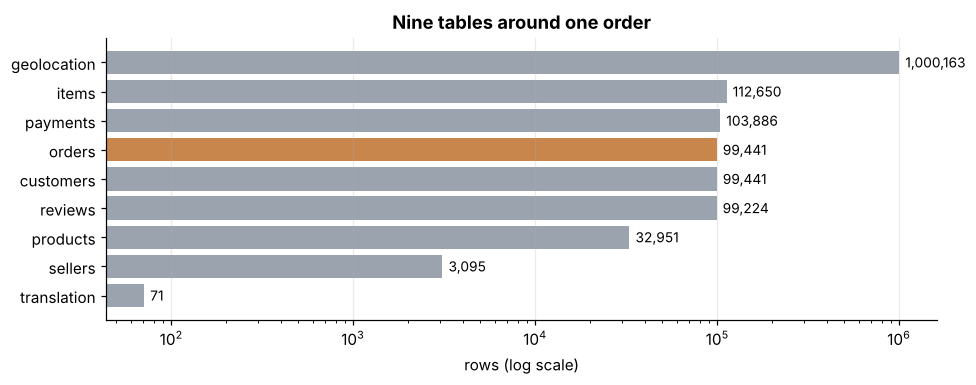

In [3]:
fig, ax = plt.subplots(figsize=(9, 3.6))
inv = inventory["rows"].sort_values()
ax.barh(inv.index, inv.values, color=[BRONZE if t == "orders" else SILVER for t in inv.index])
ax.set_xscale("log"); ax.set_xlabel("rows (log scale)"); ax.set_title("Nine tables around one order")
for y, v in enumerate(inv.values):
    ax.text(v * 1.08, y, f"{v:,}", va="center", fontsize=9)
ax.grid(axis="y", visible=False); plt.tight_layout(); plt.show()

## Step 1 · Verify quality — what is wrong with the raw data?

Before changing anything we measure four families of problems: **missing values**, **duplicates**, **outliers** (Step 7) and **inconsistencies**. Most missing values are explained by the business process (an undelivered order has no delivery date), which is why we look at their *cause* before treating them.

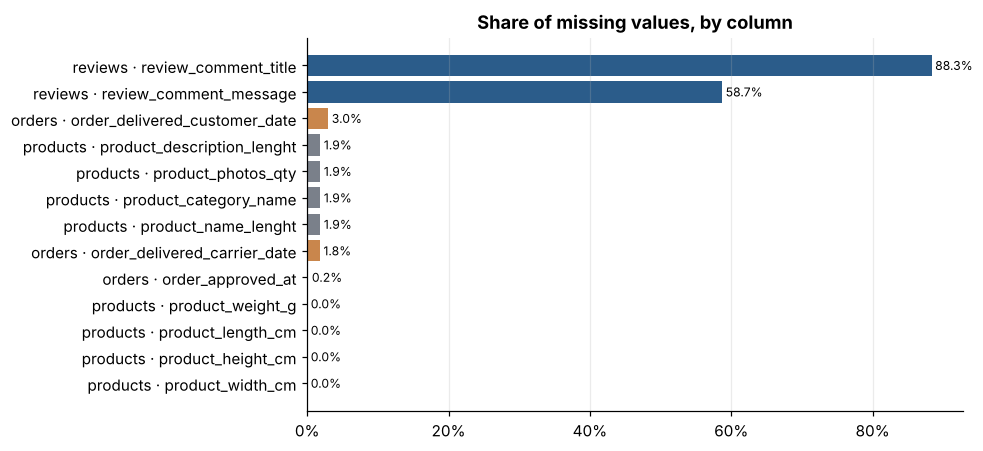

In [4]:
o, rv, pr = raw["orders"], raw["reviews"], raw["products"]
miss = pd.concat([
    o.isna().mean().rename("orders"), rv.isna().mean().rename("reviews"), pr.isna().mean().rename("products")], axis=1)
miss = miss.stack().rename("share").reset_index().rename(columns={"level_0": "column", "level_1": "table"})
miss = miss[miss["share"] > 0].sort_values("share")

fig, ax = plt.subplots(figsize=(9, 4.2))
colors = {"orders": BRONZE, "reviews": BLUE, "products": RAWC}
ax.barh(miss["table"] + " · " + miss["column"], miss["share"], color=miss["table"].map(colors))
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1)); ax.set_title("Share of missing values, by column")
for y, v in enumerate(miss["share"]):
    ax.text(v + 0.005, y, f"{v:.1%}", va="center", fontsize=8)
ax.grid(axis="y", visible=False); plt.tight_layout(); plt.show()

In [5]:
delivered = o["order_status"].eq("delivered")
checks = {
    "orders without delivery date": int(o["order_delivered_customer_date"].isna().sum()),
    "   … of which status is not 'delivered' (explained)": int((o["order_delivered_customer_date"].isna() & ~delivered).sum()),
    "reviews without comment": int(rv["review_comment_message"].isna().sum()),
    "orders with several reviews": int((rv["order_id"].value_counts() > 1).sum()),
    "review_id used twice": int(rv["review_id"].duplicated().sum()),
    "duplicate geolocation rows": int(raw["geolocation"].duplicated().sum()),
    "duplicate order_id": int(o["order_id"].duplicated().sum()),
    "carrier pickup before approval": int((o["order_delivered_carrier_date"] < o["order_approved_at"]).sum()),
    "delivered before carrier pickup": int((o["order_delivered_customer_date"] < o["order_delivered_carrier_date"]).sum()),
    "status 'delivered' but no delivery date": int((delivered & o["order_delivered_customer_date"].isna()).sum()),
    "delivery date but status not 'delivered'": int((~delivered & o["order_delivered_customer_date"].notna()).sum()),
}
pd.Series(checks, name="count").to_frame()

,count
orders without delivery date,2965
… of which status is not 'delivered' (explained),2957
reviews without comment,58247
orders with several reviews,547
review_id used twice,814
duplicate geolocation rows,261831
duplicate order_id,0
carrier pickup before approval,1359
delivered before carrier pickup,23
status 'delivered' but no delivery date,8


**Reading:** almost every missing delivery date belongs to an order that was never delivered — it is *structural*, not an error. Reviews without comment are normal (most customers only give a score). The real problems are the duplicates in geolocation and a small number of dates in an impossible order.

## Step 2 · Select — keep the periods and populations each objective needs

Two selections matter:
1. **Periods.** A trend or a model built on a month with 4 orders is meaningless. Months with fewer than 100 orders are flagged as *incomplete* (and the empty month November 2016 is made explicit).
2. **Populations.** Each target has its own population: *late delivery* is defined only for delivered orders with a real and a promised date; *poor review* only for orders that received a review; seller KPIs only for single-seller orders.

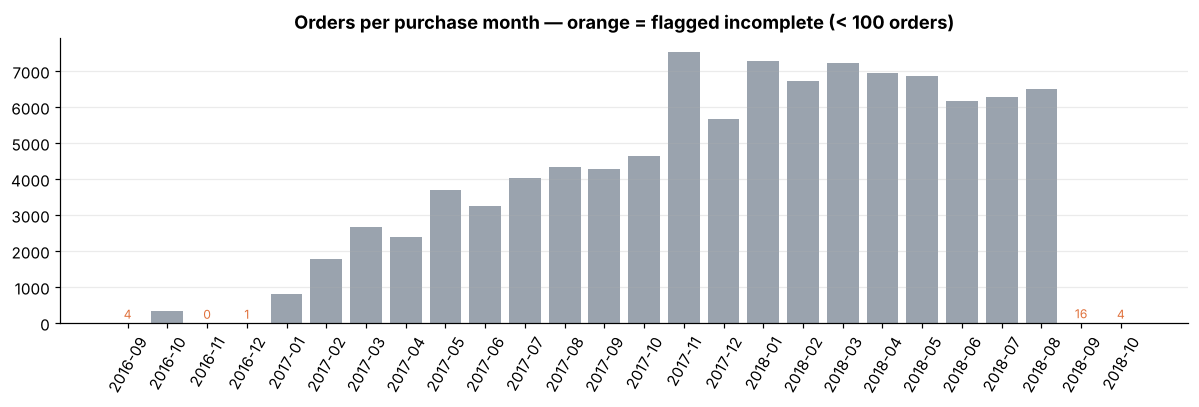

Incomplete months: ['2016-09', '2016-11', '2016-12', '2018-09', '2018-10']


In [6]:
month = o["order_purchase_timestamp"].dt.to_period("M")
months = pd.period_range(month.min(), month.max(), freq="M")
per_month = month.value_counts().reindex(months, fill_value=0)
SPARSE = 100
complete = per_month[per_month >= SPARSE].index

fig, ax = plt.subplots(figsize=(11, 3.8))
ax.bar(per_month.index.astype(str), per_month.values, color=[SILVER if v >= SPARSE else ALERT for v in per_month.values])
ax.set_title("Orders per purchase month — orange = flagged incomplete (< 100 orders)")
ax.tick_params(axis="x", rotation=60); ax.grid(axis="x", visible=False)
for x, v in enumerate(per_month.values):
    if v < SPARSE: ax.text(x, v + 120, str(v), ha="center", fontsize=8, color=ALERT)
plt.tight_layout(); plt.show()
print("Incomplete months:", [str(m) for m in per_month[per_month < SPARSE].index])

## Step 3 · Clean

### 3a · Geolocation: duplicates and impossible coordinates
The geolocation file lists several points per postcode, many of them exact duplicates. We remove duplicates, exclude points that fall outside Brazil's bounding box, and keep **one centroid per postcode**.

raw points: 1,000,163 · duplicates removed: 261,831 · outside Brazil excluded: 33


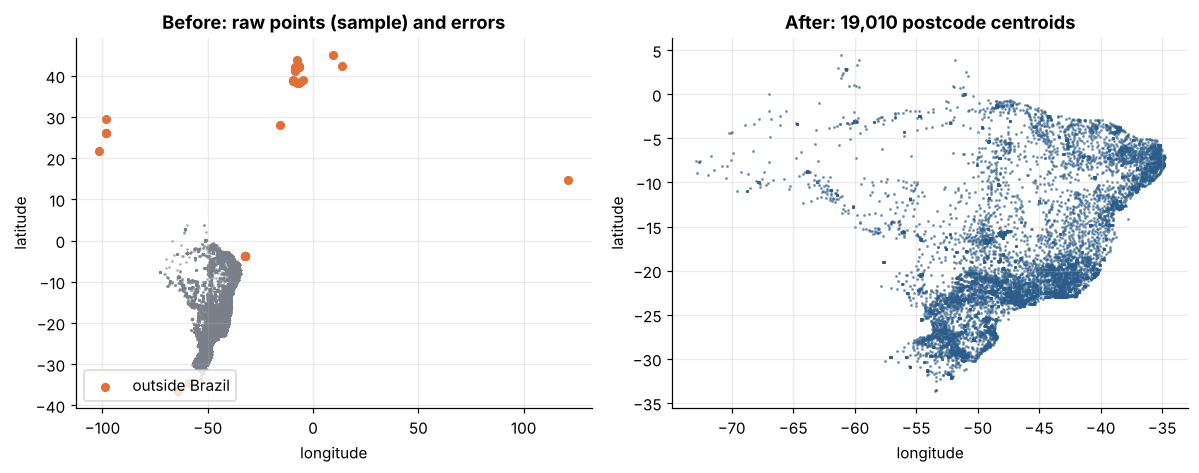

In [7]:
geo = raw["geolocation"]
geo_u = geo.drop_duplicates().copy()
BBOX = dict(lat_min=-33.8, lat_max=5.3, lng_min=-74.0, lng_max=-34.7)
inside = geo_u["geolocation_lat"].between(BBOX["lat_min"], BBOX["lat_max"]) & geo_u["geolocation_lng"].between(BBOX["lng_min"], BBOX["lng_max"])
print(f"raw points: {len(geo):,} · duplicates removed: {len(geo) - len(geo_u):,} · outside Brazil excluded: {(~inside).sum():,}")
centroid = (geo_u[inside].groupby("geolocation_zip_code_prefix")
            .agg(lat=("geolocation_lat", "mean"), lng=("geolocation_lng", "mean"), state=("geolocation_state", "first")).reset_index())

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
sample = geo_u.sample(60000, random_state=1)
axes[0].scatter(sample["geolocation_lng"], sample["geolocation_lat"], s=1, c=RAWC, alpha=.4)
axes[0].scatter(geo_u.loc[~inside, "geolocation_lng"], geo_u.loc[~inside, "geolocation_lat"], s=25, c=ALERT, label="outside Brazil")
axes[0].set_title("Before: raw points (sample) and errors"); axes[0].legend(loc="lower left")
axes[1].scatter(centroid["lng"], centroid["lat"], s=1, c=BLUE, alpha=.5)
axes[1].set_title(f"After: {len(centroid):,} postcode centroids")
for a in axes: a.set_xlabel("longitude"); a.set_ylabel("latitude")
plt.tight_layout(); plt.show()

### 3b · Inconsistent dates — flagged, never altered
When a carrier pickup is earlier than the approval, we cannot know which of the two dates is wrong. Changing either would invent data, so we **add flags** and let each analysis decide.

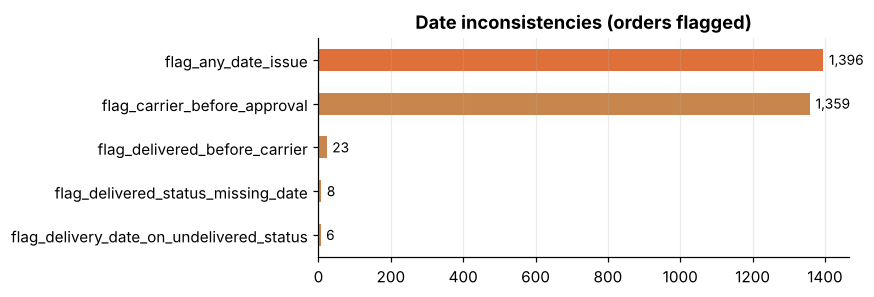

In [8]:
flags = pd.DataFrame({"order_id": o["order_id"]})
flags["flag_carrier_before_approval"] = o["order_delivered_carrier_date"] < o["order_approved_at"]
flags["flag_delivered_before_carrier"] = o["order_delivered_customer_date"] < o["order_delivered_carrier_date"]
flags["flag_delivered_status_missing_date"] = delivered & o["order_delivered_customer_date"].isna()
flags["flag_delivery_date_on_undelivered_status"] = ~delivered & o["order_delivered_customer_date"].notna()
flags["flag_any_date_issue"] = flags.filter(like="flag_").any(axis=1)
s = flags.filter(like="flag_").sum().sort_values()
ax = s.plot.barh(figsize=(8, 2.8), color=[ALERT if i == "flag_any_date_issue" else BRONZE for i in s.index], title="Date inconsistencies (orders flagged)")
for y, v in enumerate(s.values): ax.text(v + 15, y, f"{v:,}", va="center", fontsize=9)
ax.grid(axis="y", visible=False); plt.tight_layout(); plt.show()

### 3c · Product categories
Category names are in Portuguese; the official translation file gives English names. Two categories are missing from it and keep their Portuguese name. We also separate two situations that a single *"unknown"* label would mix: **products without a category** and **orders without any item**.

In [9]:
products = pr.merge(raw["translation"], on="product_category_name", how="left")
products["category"] = products["product_category_name_english"].fillna(products["product_category_name"]).fillna("unknown")
untranslated = sorted(set(pr["product_category_name"].dropna()) - set(raw["translation"]["product_category_name"]))
print("categories:", products["category"].nunique(), "· without English translation:", untranslated)
print("products without category:", int(pr["product_category_name"].isna().sum()))

categories: 74 · without English translation: ['pc_gamer', 'portateis_cozinha_e_preparadores_de_alimentos']
products without category: 610


## Step 4 · Integrate — one row per order, without inflating any amount

`items` and `payments` have several rows per order. Joining them directly multiplies the rows, and every amount is counted several times. The rule: **aggregate each table to the order level first, then join.**

In [10]:
items, pay = raw["items"], raw["payments"]
naive = o[["order_id"]].merge(items[["order_id", "price"]], on="order_id").merge(pay[["order_id", "payment_value"]], on="order_id")
print(f"Naive join: {len(naive):,} rows for {o['order_id'].nunique():,} orders "
      f"→ price total inflated by {naive['price'].sum() / items['price'].sum() - 1:.1%}")

it = items.merge(products[["product_id", "category", "product_weight_g", "product_length_cm", "product_height_cm", "product_width_cm"]], on="product_id", how="left")
it["volume_cm3"] = it["product_length_cm"] * it["product_height_cm"] * it["product_width_cm"]
g = it.groupby("order_id")
item_agg = g.agg(item_count=("order_item_id", "count"), product_count=("product_id", "nunique"), seller_count=("seller_id", "nunique"),
                 item_price_total=("price", "sum"), freight_total=("freight_value", "sum"),
                 weight_mean_g=("product_weight_g", "mean"), volume_mean_cm3=("volume_cm3", "mean")).reset_index()
item_agg["primary_category"] = g["category"].agg(lambda s: s.mode().iloc[0] if not s.mode().empty else "unknown").values
first = items.sort_values("order_item_id").drop_duplicates("order_id")[["order_id", "seller_id"]].rename(columns={"seller_id": "main_seller_id"})
pay_agg = pay.groupby("order_id").agg(payment_rows=("payment_sequential", "count"), payment_type_count=("payment_type", "nunique"),
                                      installments_max=("payment_installments", "max"), payment_total=("payment_value", "sum")).reset_index()
# one review per order: the latest answer, then review_id to break ties
review = rv.sort_values(["order_id", "review_answer_timestamp", "review_id"]).drop_duplicates("order_id", keep="last")

df = (o.merge(raw["customers"], on="customer_id", how="left", validate="many_to_one")
        .merge(item_agg, on="order_id", how="left", validate="one_to_one")
        .merge(first, on="order_id", how="left", validate="one_to_one")
        .merge(pay_agg, on="order_id", how="left", validate="one_to_one")
        .merge(review[["order_id", "review_score", "review_comment_title", "review_comment_message"]], on="order_id", how="left", validate="one_to_one")
        .merge(flags, on="order_id", how="left", validate="one_to_one"))
for c in ["item_count", "product_count", "seller_count", "payment_rows", "payment_type_count"]:
    df[c] = df[c].fillna(0).astype(int)
df["primary_category"] = np.where(df["item_count"].eq(0), "no_items", df["primary_category"].fillna("unknown"))

proof = pd.DataFrame({"raw files": [items["price"].sum(), items["freight_value"].sum(), pay["payment_value"].sum(), len(o)],
                      "prepared table": [df["item_price_total"].sum(), df["freight_total"].sum(), df["payment_total"].sum(), df["order_id"].nunique()]},
                     index=["item prices (R$)", "freight (R$)", "payments (R$)", "orders"]).round(2)
assert np.allclose(proof["raw files"], proof["prepared table"]), "Totals changed during integration"
print("One row per order:", len(df) == df["order_id"].nunique())
proof

Naive join: 117,601 rows for 99,441 orders → price total inflated by 4.5%


One row per order: True


,raw files,prepared table
item prices (R$),13591643.70,13591643.70
freight (R$),2251909.54,2251909.54
payments (R$),16008872.12,16008872.12
orders,99441.00,99441.00


In [11]:
print("Orders with several sellers:", int((df["seller_count"] > 1).sum()),
      "→ excluded from seller KPIs, analysed in their own table")
print("Orders without items:", int((df["item_count"] == 0).sum()), "· without review:", int(df["review_score"].isna().sum()))

Orders with several sellers: 1278 → excluded from seller KPIs, analysed in their own table
Orders without items: 775 · without review: 768


## Step 5 · Construct — targets and new variables

| Variable | Definition | Known at approval? |
|---|---|---|
| `is_late` | delivery **day** after the promised day — only for delivered orders with both dates | target |
| `is_poor_review` | review score 1 or 2 — only for reviewed orders | target |
| `delivery_days` | purchase → delivery, delivered orders only | outcome (analysis only) |
| `promised_days` | purchase → promised date (shown to the customer at purchase) | **yes** |
| `distance_km` | customer ↔ main seller, from postcode centroids | **yes** |

In [12]:
df["late_label_eligible"] = delivered.values & df["order_delivered_customer_date"].notna() & df["order_estimated_delivery_date"].notna()
df["late_days"] = (df["order_delivered_customer_date"].dt.normalize() - df["order_estimated_delivery_date"].dt.normalize()).dt.days
df["is_late"] = np.where(df["late_label_eligible"], (df["late_days"] > 0).astype(float), np.nan)
df["is_poor_review"] = np.where(df["review_score"].notna(), (df["review_score"] <= 2).astype(float), np.nan)
df["delivery_days"] = ((df["order_delivered_customer_date"] - df["order_purchase_timestamp"]).dt.total_seconds() / 86400).where(df["late_label_eligible"])
df["promised_days"] = (df["order_estimated_delivery_date"].dt.normalize() - df["order_purchase_timestamp"].dt.normalize()).dt.days
df["approval_delay_h"] = (df["order_approved_at"] - df["order_purchase_timestamp"]).dt.total_seconds() / 3600
df["purchase_month"] = df["order_purchase_timestamp"].dt.to_period("M")

cg = centroid.set_index("geolocation_zip_code_prefix")
sel = raw["sellers"].set_index("seller_id")["seller_zip_code_prefix"]
clat, clng = df["customer_zip_code_prefix"].map(cg["lat"]), df["customer_zip_code_prefix"].map(cg["lng"])
szip = df["main_seller_id"].map(sel)
slat, slng = szip.map(cg["lat"]), szip.map(cg["lng"])
p1, p2 = np.radians(clat), np.radians(slat)
df["distance_km"] = 2 * 6371 * np.arcsin(np.sqrt(np.sin((p2 - p1) / 2) ** 2 + np.cos(p1) * np.cos(p2) * np.sin(np.radians(slng - clng) / 2) ** 2))
df["same_state"] = (df["customer_state"] == df["main_seller_id"].map(raw["sellers"].set_index("seller_id")["seller_state"])).astype(int)

lab = df[df["late_label_eligible"]]
print(f"late: {int(lab['is_late'].sum()):,} of {len(lab):,} delivered orders = {lab['is_late'].mean():.2%}")
print(f"poor review: {df['is_poor_review'].mean():.2%} of {df['is_poor_review'].notna().sum():,} reviewed orders")

late: 6,534 of 96,470 delivered orders = 6.77%
poor review: 14.69% of 98,673 reviewed orders


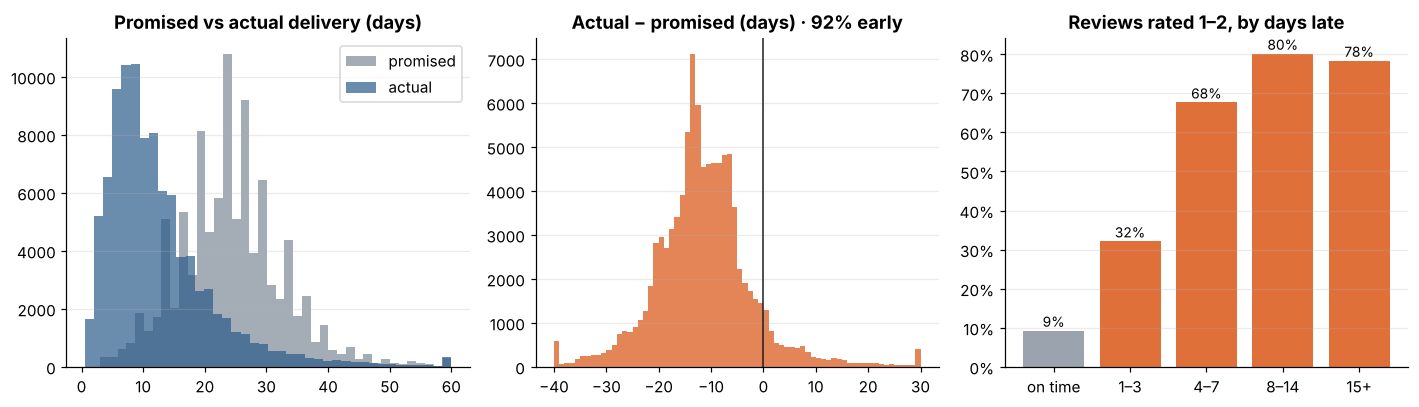

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
axes[0].hist(lab["promised_days"].clip(upper=60), bins=40, color=SILVER, alpha=.9, label="promised")
axes[0].hist(lab["delivery_days"].clip(upper=60), bins=40, color=BLUE, alpha=.7, label="actual")
axes[0].set_title("Promised vs actual delivery (days)"); axes[0].legend()
gap = lab["late_days"].clip(-40, 30)
axes[1].hist(gap, bins=70, color=[ALERT], alpha=.85); axes[1].axvline(0, color=INK, lw=1)
axes[1].set_title(f"Actual − promised (days) · {(lab['late_days'] < 0).mean():.0%} early")
r = lab[lab["review_score"].notna()].copy()
r["delay"] = pd.cut(r["late_days"], [-1000, 0, 3, 7, 14, 1000], labels=["on time", "1–3", "4–7", "8–14", "15+"])
share = r.groupby("delay", observed=True)["is_poor_review"].mean()
axes[2].bar(share.index.astype(str), share.values, color=[SILVER] + [ALERT] * 4)
axes[2].yaxis.set_major_formatter(mtick.PercentFormatter(1)); axes[2].set_title("Reviews rated 1–2, by days late")
for x, v in enumerate(share.values): axes[2].text(x, v + .01, f"{v:.0%}", ha="center", fontsize=9)
for a in axes: a.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

**Reading:** promises are cautious (most orders arrive well before the promised day), but as soon as an order is late, satisfaction collapses — that is why both targets are modelled.

## Step 6 · Missing values — explain, then impute or keep

| Variable | Cause | Treatment |
|---|---|---|
| delivery dates | order not delivered | **not imputed**; late label left empty |
| review score / comment | customer did not review / did not write | kept missing; never read as satisfied |
| product weight & size | attribute not filled in | median **of the same category** (training period) + indicator |
| approval delay, payment, distance, price, freight | not approved / no record / postcode without coordinates / no items | training-period median + indicator |

Indicators (`*_missing`) let the model learn from the gap itself. Every imputation value is computed on the **training period only** (Step 9 defines it), so nothing from the future leaks into the past.

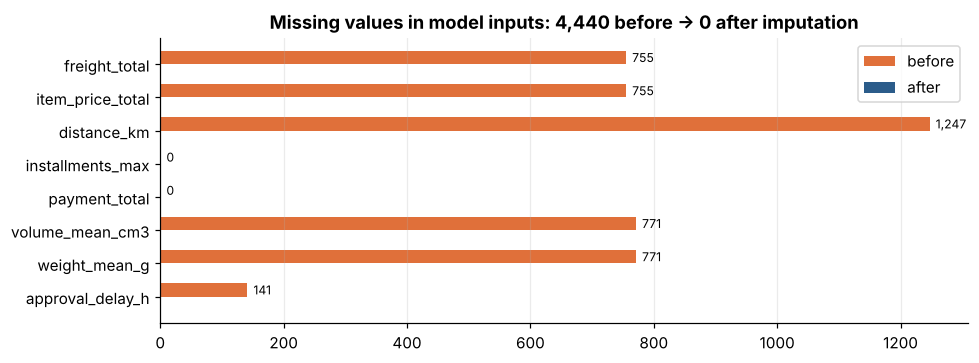

In [14]:
TRAIN_END, VALID_END, TEST_END = "2018-01-01", "2018-04-01", "2018-09-01"
m = df[df["purchase_month"].isin(complete)].copy()
t = m["order_purchase_timestamp"]
m["split"] = np.select([t < TRAIN_END, t < VALID_END, t < TEST_END], ["train", "valid", "test"], "drop")
m = m[m["split"] != "drop"].copy()
tr = m["split"].eq("train")

num = ["approval_delay_h", "weight_mean_g", "volume_mean_cm3", "payment_total", "installments_max", "distance_km", "item_price_total", "freight_total"]
before = m[num].isna().sum()
for c in ["weight_mean_g", "volume_mean_cm3"]:
    m[f"{c}_missing"] = m[c].isna().astype(int)
    m[c] = m[c].fillna(m["primary_category"].map(m[tr].groupby("primary_category")[c].median())).fillna(m.loc[tr, c].median())
for c in ["approval_delay_h", "payment_total", "installments_max", "distance_km", "item_price_total", "freight_total"]:
    m[f"{c}_missing"] = m[c].isna().astype(int)
    m[c] = m[c].fillna(m.loc[tr, c].median())
after = m[num].isna().sum()

fig, ax = plt.subplots(figsize=(9, 3.4))
y = np.arange(len(num))
ax.barh(y + .2, before.values, height=.4, color=ALERT, label="before")
ax.barh(y - .2, after.values, height=.4, color=BLUE, label="after")
ax.set_yticks(y, num); ax.set_title(f"Missing values in model inputs: {int(before.sum()):,} before → {int(after.sum())} after imputation"); ax.legend()
for i, v in enumerate(before.values): ax.text(v + 10, i + .2, f"{v:,}", va="center", fontsize=8)
ax.grid(axis="y", visible=False); plt.tight_layout(); plt.show()

## Step 7 · Outliers — real values, transformed rather than deleted

Extreme values are detected with a wide fence (Q3 + 3·IQR, training period). They are **plausible** (an expensive order, heavy furniture, a distant seller, a payment approved weeks later), so deleting them would bias the data. For the models we apply `log1p` and cap at the 0.5th / 99.5th percentiles of the training period.

In [15]:
SKEWED = ["item_price_total", "freight_total", "payment_total", "weight_mean_g", "volume_mean_cm3", "approval_delay_h", "distance_km"]
rows = []
for c in SKEWED:
    q1, q3 = m.loc[tr, c].quantile([.25, .75]); fence = q3 + 3 * (q3 - q1)
    x = np.log1p(m[c].clip(lower=0)); lo, hi = x[tr].quantile([.005, .995])
    m[f"{c}_log"] = x.clip(lo, hi)
    rows.append({"variable": c, "median": round(m[c].median(), 2), "max": round(m[c].max(), 1), "extreme (> Q3+3·IQR)": int((m[c] > fence).sum())})
pd.DataFrame(rows).set_index("variable")

,median,max,extreme (> Q3+3·IQR)
variable,,,
item_price_total,85.00,13440.0,4113
freight_total,17.09,1795.0,5603
payment_total,105.29,13664.1,4073
weight_mean_g,700.00,40425.0,9465
volume_mean_cm3,6600.00,296208.0,3294
approval_delay_h,0.34,4509.2,4392
distance_km,440.65,3579.9,799


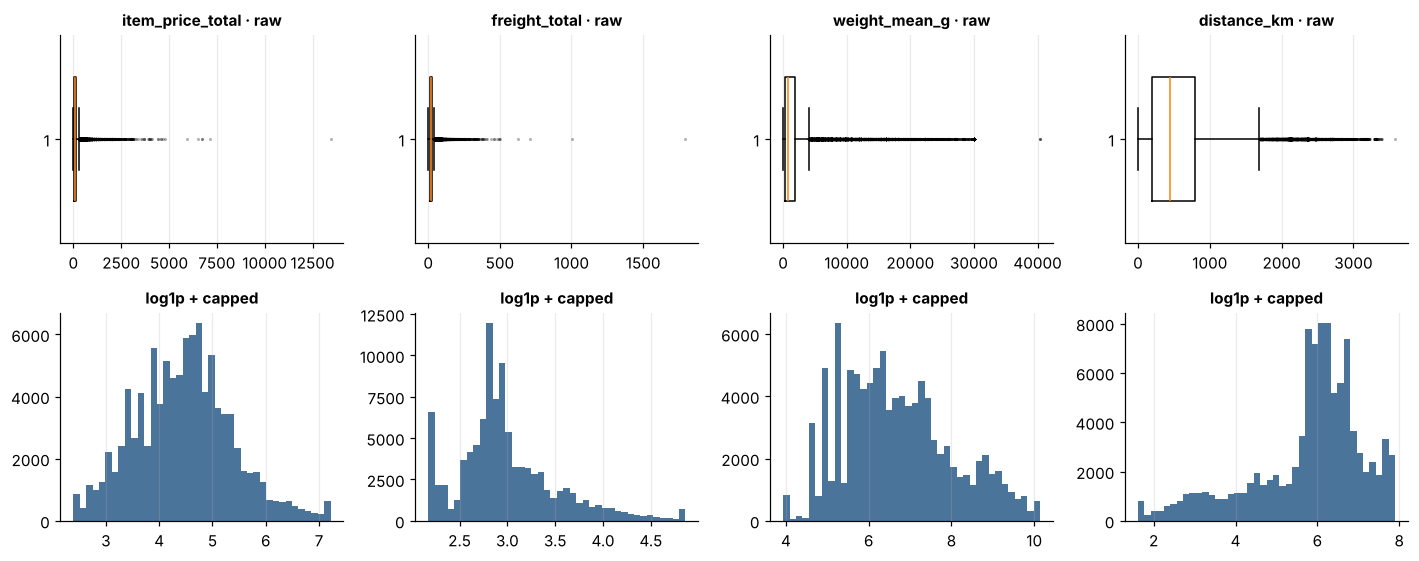

In [16]:
show = ["item_price_total", "freight_total", "weight_mean_g", "distance_km"]
fig, axes = plt.subplots(2, 4, figsize=(13, 5.2))
for i, c in enumerate(show):
    axes[0, i].boxplot(m[c].dropna(), vert=False, widths=.6, flierprops=dict(marker=".", markersize=2, alpha=.3, color=ALERT))
    axes[0, i].set_title(f"{c} · raw", fontsize=10)
    axes[1, i].hist(m[f"{c}_log"], bins=40, color=BLUE, alpha=.85)
    axes[1, i].set_title("log1p + capped", fontsize=10)
for a in axes.flat: a.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

## Step 8 · Encoding — preparing variables for the models

* **One-hot encoding** for the customer state (27 values).
* **Smoothed target encoding** for high-cardinality variables — product category (74 values) and seller (~3,000): each value is replaced by its historical late (or poor-review) rate, pulled towards the global rate when it has few orders (smoothing = 20).
  * Learned on the **training period only**; an unseen seller gets the global rate.
  * For the training rows themselves, the encoding is computed **out-of-fold** (5 folds), so a row never sees its own target.

In [17]:
def target_encode(keys_fit, y_fit, keys_apply, prior, k=20):
    st = pd.DataFrame({"k": keys_fit.values, "y": y_fit.values}).groupby("k")["y"].agg(["sum", "count"])
    return keys_apply.map((st["sum"] + prior * k) / (st["count"] + k)).fillna(prior).astype(float)

m["customer_state"] = m["customer_state"].fillna("unknown")
m = pd.concat([m, pd.get_dummies(m["customer_state"], prefix="state", dtype=int)], axis=1)
lab_tr = tr & m["is_late"].notna()
prior = m.loc[lab_tr, "is_late"].mean()
rng = np.random.default_rng(42)
for col, name in [("primary_category", "te_category_late"), ("main_seller_id", "te_seller_late")]:
    enc = target_encode(m.loc[lab_tr, col], m.loc[lab_tr, "is_late"], m[col], prior)   # valid / test rows
    idx = m.index[tr]; folds = rng.permutation(np.arange(len(idx)) % 5)
    for f in range(5):                                                                     # train rows: out-of-fold
        fit = idx[folds != f]; fit = fit[m.loc[fit, "is_late"].notna()]
        enc.loc[idx[folds == f]] = target_encode(m.loc[fit, col], m.loc[fit, "is_late"], m.loc[idx[folds == f], col], prior)
    m[name] = enc
print(f"global late rate (train): {prior:.2%}")
m.loc[tr].groupby("primary_category")["te_category_late"].mean().sort_values().iloc[[0, 1, 2, -3, -2, -1]].round(4).to_frame("encoded late rate (examples)")

global late rate (train): 5.62%


,encoded late rate (examples)
primary_category,
market_place,0.0217
art,0.0251
fixed_telephony,0.0291
audio,0.1029
cine_photo,0.1048
construction_tools_lights,0.1591


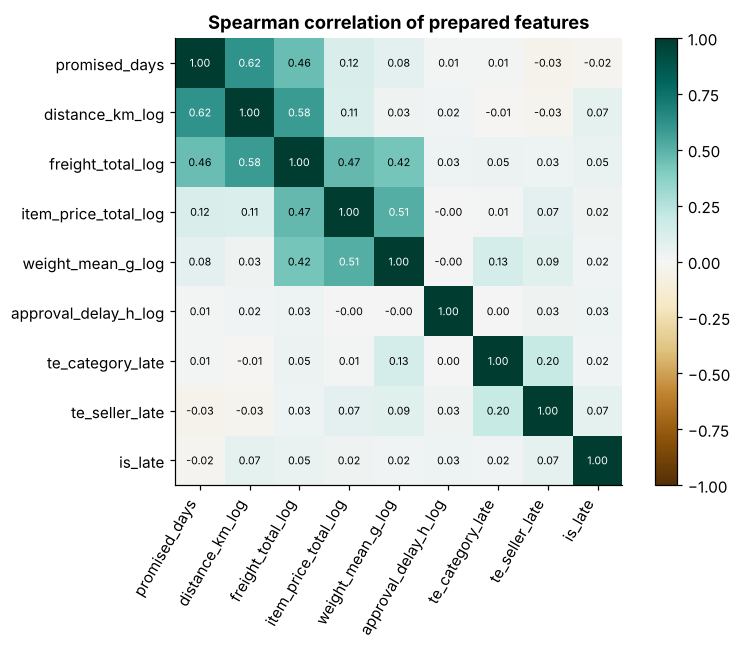

In [18]:
feat_corr = ["promised_days", "distance_km_log", "freight_total_log", "item_price_total_log", "weight_mean_g_log", "approval_delay_h_log",
             "te_category_late", "te_seller_late", "is_late"]
corr = m.loc[m["is_late"].notna(), feat_corr].corr(method="spearman")
fig, ax = plt.subplots(figsize=(7.5, 6))
im = ax.imshow(corr, cmap="BrBG", vmin=-1, vmax=1)
ax.set_xticks(range(len(feat_corr)), feat_corr, rotation=60, ha="right"); ax.set_yticks(range(len(feat_corr)), feat_corr)
for i in range(len(feat_corr)):
    for j in range(len(feat_corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7, color="white" if abs(corr.iloc[i, j]) > .5 else "black")
ax.set_title("Spearman correlation of prepared features"); ax.grid(False); plt.colorbar(im, fraction=.046); plt.tight_layout(); plt.show()

## Step 9 · Chronological split and leakage control

The split is **by time, never random**: the model is always tested on months it has never seen, as it would be in real use.

| Split | Period |
|---|---|
| train | Oct 2016 – Dec 2017 |
| validation | Jan – Mar 2018 |
| test | Apr – Aug 2018 |

The model table keeps **only information known when the order is approved**. A check fails if any post-approval column is present.

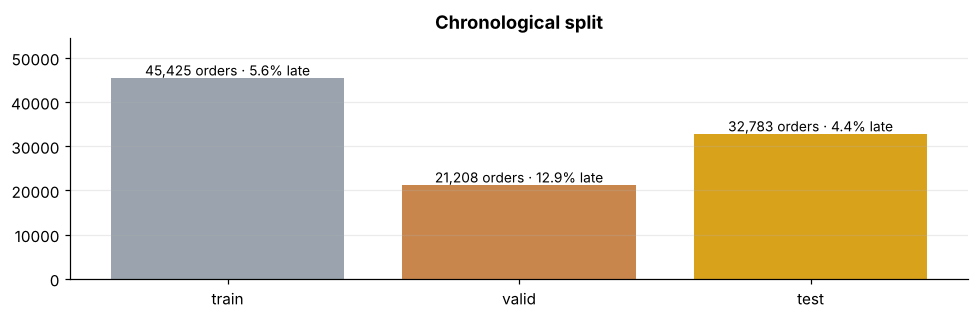

,orders,late_rate,poor_review_rate
split,,,
train,45425,0.0562,0.1457
valid,21208,0.1288,0.1969
test,32783,0.0442,0.1158


In [19]:
summary = m.groupby("split").agg(orders=("order_id", "size"), late_rate=("is_late", "mean"), poor_review_rate=("is_poor_review", "mean")).reindex(["train", "valid", "test"])
fig, ax = plt.subplots(figsize=(9, 3))
ax.bar(summary.index, summary["orders"], color=[SILVER, BRONZE, GOLD])
for x, (n, lr) in enumerate(zip(summary["orders"], summary["late_rate"])):
    ax.text(x, n + 600, f"{n:,} orders · {lr:.1%} late", ha="center", fontsize=9)
ax.set_title("Chronological split"); ax.set_ylim(0, summary["orders"].max() * 1.2); ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()
summary.round(4)

In [20]:
FEATURES = (["promised_days", "purchase_weekday", "purchase_hour", "purchase_month_num", "item_count", "product_count", "seller_count",
             "payment_rows", "payment_type_count", "installments_max", "same_state"]
            + [f"{c}_log" for c in SKEWED] + [c for c in m.columns if c.endswith("_missing")]
            + [c for c in m.columns if c.startswith("state_")] + ["te_category_late", "te_seller_late"])
m["purchase_weekday"] = m["order_purchase_timestamp"].dt.dayofweek
m["purchase_hour"] = m["order_purchase_timestamp"].dt.hour
m["purchase_month_num"] = m["order_purchase_timestamp"].dt.month

FORBIDDEN = ["order_status", "order_delivered_carrier_date", "order_delivered_customer_date", "order_estimated_delivery_date", "delivery_days",
             "late_days", "review_score", "review_comment_title", "review_comment_message"] + [c for c in m.columns if c.startswith("flag_")]
leaks = [c for c in FEATURES if c in FORBIDDEN]
assert not leaks, f"Leakage: {leaks}"
assert m[FEATURES].isna().sum().sum() == 0, "Missing values remain in the features"
print(f"{len(FEATURES)} features for the late-delivery model · no post-approval column · no missing value")
print("(src/build_model_features.py builds 61: it adds the poor-review encodings, seller-state encoding, seller history size and a weekend flag)")

55 features for the late-delivery model · no post-approval column · no missing value
(src/build_model_features.py builds 61: it adds the poor-review encodings, seller-state encoding, seller history size and a weekend flag)


## Step 10 · Text — review documents and French translation

Every review with free text (a comment **or** a title) becomes a JSON document that keeps its context (order, score, month, state, category, delivery outcome). The text is in Portuguese; a French translation is produced **locally** by `src/translate_reviews.py` (two open MarianMT models, PT → EN → FR), keeping the original next to the translation.

review documents: 42,687 (40,950 with a comment, 1,737 with only a title)


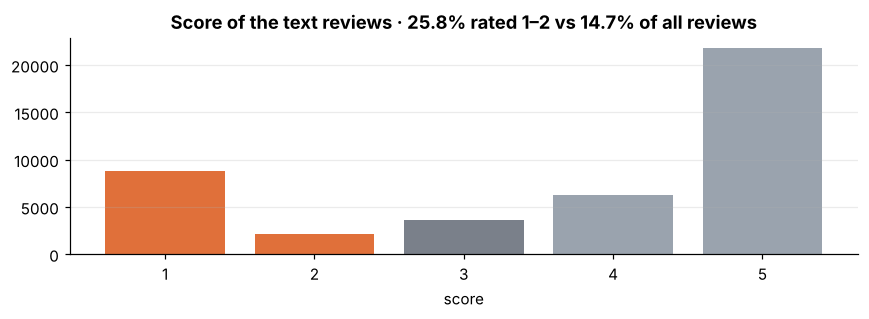

In [21]:
has_msg = rv["review_comment_message"].fillna("").str.strip().ne("")
has_title = rv["review_comment_title"].fillna("").str.strip().ne("")
docs = rv[has_msg | has_title]
print(f"review documents: {len(docs):,} ({has_msg.sum():,} with a comment, {(has_title & ~has_msg).sum():,} with only a title)")
written = docs["review_score"].le(2).mean(); overall = rv["review_score"].le(2).mean()
fig, ax = plt.subplots(figsize=(8, 3))
cnt = docs["review_score"].value_counts().sort_index()
ax.bar(cnt.index.astype(str), cnt.values, color=[ALERT, ALERT, RAWC, SILVER, SILVER])
ax.set_title(f"Score of the text reviews · {written:.1%} rated 1–2 vs {overall:.1%} of all reviews"); ax.set_xlabel("score")
ax.grid(axis="x", visible=False); plt.tight_layout(); plt.show()

In [22]:
sample = ROOT / "quality" / "translation_sample_for_review.csv"
if sample.exists():
    ex = pd.read_csv(sample, sep=";", encoding="utf-8-sig")
    ex = ex[ex["texte_pt"].fillna("").str.len().between(30, 140)].head(4)[["review_score", "texte_pt", "texte_fr"]]
    display(ex.rename(columns={"texte_pt": "original (PT)", "texte_fr": "translation (FR)"}))
else:
    print("Run src/translate_reviews.py to produce the French translation.")

,review_score,original (PT),translation (FR)
0,1,"Dos dois produtos comprados, foi entregue apen...","Parmi les deux produits achetés, un seul a été..."
1,4,"Ótima loja para parceria: rápidíssima, produto...",Grand magasin pour le partenariat: très rapide...
5,1,"Comprei o relógio, unissex e enviaram um relóg...","J'ai acheté la montre, unisexe, et ils ont env..."
7,5,O kit mochila patrulha canina é lindo!! Meu ne...,Le sac à dos de patrouille canine est magnifiq...


## Step 11 · Format — save and check

The prepared data is written to `data/notebook_run/` (the pipeline outputs in `data/silver` and `data/gold` are left untouched). A final set of assertions confirms the main rules.

In [23]:
keep = ["order_id", "order_purchase_timestamp", "split", "late_label_eligible", "is_late", "is_poor_review"] + FEATURES
for s_ in ["train", "valid", "test"]:
    m.loc[m["split"] == s_, keep].to_csv(OUT / f"features_{s_}.csv.gz", index=False, compression="gzip")
analysis_cols = [c for c in df.columns if not c.startswith("review_comment")]
df[analysis_cols].assign(purchase_month=df["purchase_month"].astype(str)).to_csv(OUT / "orders_analysis.csv.gz", index=False, compression="gzip")

final = pd.Series({
    "raw files are the original release": bool(inventory["original release"].all()),
    "one row per order (99,441)": len(df) == 99441 and df["order_id"].is_unique,
    "amounts equal the raw files": bool(np.allclose(proof["raw files"], proof["prepared table"])),
    "late = 6,534 of 96,470 delivered": int(df["is_late"].sum()) == 6534 and int(df["late_label_eligible"].sum()) == 96470,
    "no late label without an observed delivery": bool(df.loc[~df["late_label_eligible"], "is_late"].isna().all()),
    "incomplete months excluded from modeling": not m["purchase_month"].isin(per_month[per_month < SPARSE].index).any(),
    "no leakage column in features": not leaks,
    "no missing value in features": bool(m[FEATURES].isna().sum().sum() == 0),
}, name="passed").to_frame()
assert final["passed"].all()
final

,passed
raw files are the original release,True
"one row per order (99,441)",True
amounts equal the raw files,True
"late = 6,534 of 96,470 delivered",True
no late label without an observed delivery,True
incomplete months excluded from modeling,True
no leakage column in features,True
no missing value in features,True


## Summary

* **Collect & verify:** 9 original files, fingerprints checked; missing values are mostly structural, duplicates concentrated in geolocation, 1,396 orders with inconsistent dates.
* **Select:** 5 incomplete months flagged and excluded from modeling; each target has its own population.
* **Clean:** geolocation de-duplicated and restricted to Brazil; dates flagged, never altered; `no_items` distinct from `unknown`.
* **Integrate:** items and payments aggregated before joining — one row per order, amounts identical to the raw files.
* **Construct:** late and poor-review targets, promised delay, distance, durations.
* **Missing values & outliers:** explained by their cause; imputed with training medians and indicators; extreme values log-transformed and capped instead of deleted.
* **Encoding & split:** one-hot and out-of-fold target encoding; chronological train / validation / test; no future information in the features.

The prepared files feed the modeling notebook (DS1.1 late delivery, DS1.2 poor review).